# Практическое занятие 04. Классификация и метрики качества

Цель занятия: научиться выбирать метрику под задачу классификации и увидеть в коде, почему доля правильных ответов обманывает, когда один класс встречается гораздо чаще другого.

Основа — глава 3 книги Орельена Жерона «Прикладное машинное обучение с помощью Scikit-Learn и TensorFlow», стр. 121–150. Теорию разбирали на лекции, здесь — только код.

План:

- MNIST: загрузка, просмотр изображений, распределение классов — 8 мин;
- бинарный классификатор «5 / не 5» и «глупый» классификатор — 10 мин;
- матрица ошибок, точность, полнота, F1, порог решения, ROC-кривая и AUC — 22 мин;
- многоклассовая классификация, анализ ошибок, сравнение моделей — 15 мин;
- задание: поиск мошеннических операций — 15 мин;
- факультативно, для самостоятельного чтения: macro- и micro-усреднение метрик.

In [1]:
import sys

import matplotlib
import numpy as np
import pandas as pd
import scipy
import sklearn

sys.version, np.__version__, pd.__version__, matplotlib.__version__, scipy.__version__, sklearn.__version__

('3.8.10 (default, Jun 22 2022, 20:18:18) \n[GCC 9.4.0]',
 '1.24.4',
 '2.0.3',
 '3.7.5',
 '1.10.1',
 '1.3.2')

In [2]:
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (8, 5)

# MNIST

Книга: гл. 3, стр. 121–124.

MNIST — 70 000 рукописных цифр 28×28 пикселей, собранных у школьников и сотрудников Бюро переписи США. Это «Hello, world» машинного обучения: на нём проверяют почти любой новый классификатор.

## Загрузка: [`fetch_openml`](https://scikit-learn.org/1.3/modules/generated/sklearn.datasets.fetch_openml.html)

[OpenML](https://www.openml.org/) — открытая онлайн-платформа, где исследователи публикуют наборы данных, задачи и результаты экспериментов машинного обучения. У каждого набора там есть имя, номер и описание; MNIST лежит под именем [`mnist_784`](https://www.openml.org/d/554), номер 554.

Функция `fetch_openml` скачивает набор с OpenML по имени или номеру, сохраняет его в локальный кеш `~/scikit_learn_data` и возвращает объект `Bunch` — словарь с признаками, метками и описанием набора.

Первый вызов скачивает набор (около 3 минут), следующие берут его из кеша за секунды. `as_frame=False` возвращает массивы NumPy, а не `DataFrame`: для изображений так удобнее.

In [3]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
mnist.keys()

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

In [4]:
X, y = mnist['data'], mnist['target']
X.shape, X.dtype, y.shape, y.dtype

((70000, 784), dtype('int64'), (70000,), dtype('O'))

Каждая строка `X` — одно изображение, вытянутое в вектор из 784 = 28 × 28 яркостей от 0 (белый) до 255 (чёрный). Метки пришли **строками**:

In [5]:
y[:10]

array(['5', '0', '4', '1', '9', '2', '1', '3', '1', '4'], dtype=object)

Строковые метки неудобны: `y == 5` всюду даст `False`. Переводим их в целые числа:

In [6]:
y = y.astype(np.uint8)
y[:10], np.unique(y)

(array([5, 0, 4, 1, 9, 2, 1, 3, 1, 4], dtype=uint8),
 array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8))

## Просмотр изображений

Чтобы увидеть цифру, вектор превращаем обратно в матрицу 28 × 28. Ненулевые яркости уже на матрице чисел рисуют пятёрку; `printoptions` расширяет строку вывода, чтобы матрица не переносилась:

In [7]:
with np.printoptions(linewidth=150):
    print(X[0].reshape(28, 28))

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136 175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253 225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251  93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 182 247 241   0   

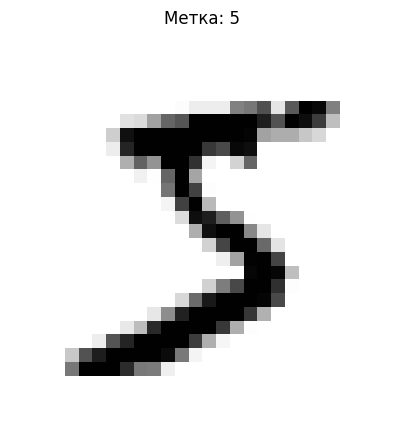

In [8]:
plt.imshow(X[0].reshape(28, 28), cmap='binary')
plt.title(f'Метка: {y[0]}')
plt.axis('off')
plt.show()

Функция для сетки цифр пригодится дальше — в анализе ошибок:

In [9]:
def plot_digits(images, labels, n_cols=6):
    """Рисует изображения цифр сеткой с подписями.

    Args:
        images: Массив изображений формы (n, 784).
        labels: Подписи изображений.
        n_cols: Число столбцов сетки.
    """
    n_rows = int(np.ceil(len(images) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(1.5 * n_cols, 1.7 * n_rows))

    for ax in axes.flat:
        ax.axis('off')

    for ax, image, label in zip(axes.flat, images, labels):
        ax.imshow(image.reshape(28, 28), cmap='binary')
        ax.set_title(str(label))

    plt.show()

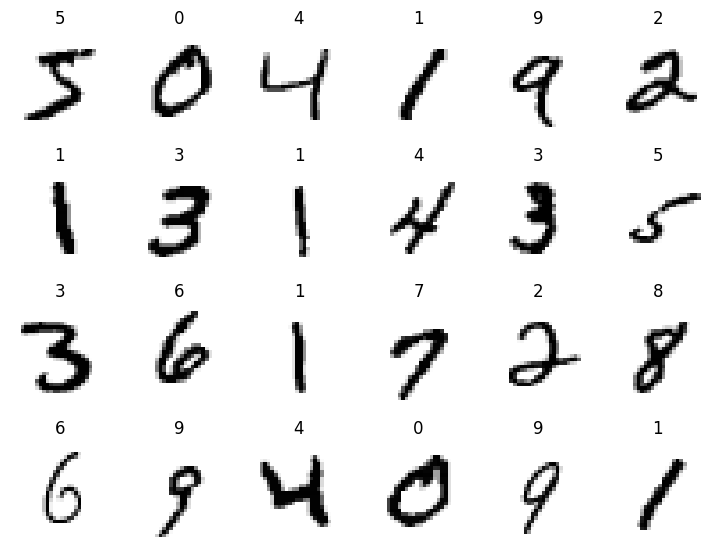

In [10]:
plot_digits(X[:24], y[:24])

## Распределение классов

Цифр каждого класса примерно поровну — около 10 % на класс:

In [11]:
class_counts = pd.Series(y).value_counts().sort_index()
class_counts

0    6903
1    7877
2    6990
3    7141
4    6824
5    6313
6    6876
7    7293
8    6825
9    6958
Name: count, dtype: int64

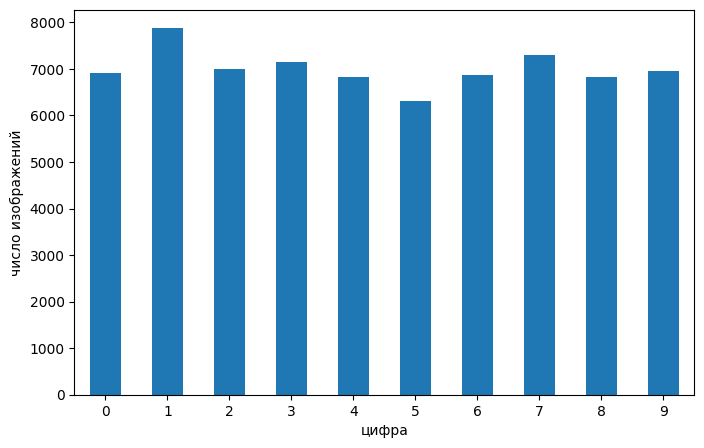

In [12]:
class_counts.plot.bar(rot=0, xlabel='цифра', ylabel='число изображений')
plt.show()

## Обучающая и тестовая выборки

MNIST уже разделён: первые 60 000 изображений — обучающая выборка, последние 10 000 — тестовая. Обучающая выборка перемешана, поэтому блоки перекрёстной проверки получатся похожими. Тест, как и в практике 03, откладываем до конца и в этом блокноте не трогаем.

In [13]:
X_train, X_test, y_train, y_test = X[:60_000], X[60_000:], y[:60_000], y[60_000:]
X_train.shape, X_test.shape

((60000, 784), (10000, 784))

# Бинарный классификатор «5 / не 5»

Книга: гл. 3, стр. 124–127.

Упростим задачу: распознаём одну цифру — пятёрку. Классов два: «5» (положительный, `True`) и «не 5» (отрицательный, `False`).

In [14]:
y_train_5 = (y_train == 5)
y_train_5[:10], y_train_5.mean()

(array([ True, False, False, False, False, False, False, False, False,
        False]),
 0.09035)

## [`SGDClassifier`](https://scikit-learn.org/1.3/modules/generated/sklearn.linear_model.SGDClassifier.html)

Документация модели — по ссылке в заголовке. `SGDClassifier` — линейный классификатор, обучаемый стохастическим градиентным спуском (англ. *stochastic gradient descent*, SGD): он обрабатывает образцы по одному и поэтому быстро учится даже на больших наборах. Градиентный спуск разберём в практике 06.

### Математическая основа

Образец — вектор признаков $x = (x_1, x_2, \dots, x_n)$; у MNIST $n = 784$, по признаку на пиксель. Модель вычисляет линейную комбинацию признаков:

$$z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b,$$

или в векторном виде:

$$z = w^T x + b,$$

где:

- $w$ — обучаемые веса признаков (атрибут `coef_`);
- $b$ — свободный коэффициент (атрибут `intercept_`);
- $x$ — признаки образца;
- $z$ — оценка, по которой модель выбирает класс.

В бинарной классификации предсказание устроено так:

$$\hat{y} = \begin{cases} 1, & z \ge 0, \\ 0, & z < 0. \end{cases}$$

Модель не обязана выдавать вероятность. При функции потерь по умолчанию `loss='hinge'` это линейный метод опорных векторов, и $z$ — оценка положения образца относительно разделяющей гиперплоскости $w^T x + b = 0$; при `loss='log_loss'` получается логистическая регрессия, у которой есть `predict_proba`. Стохастический градиентный спуск — не модель, а способ подобрать $w$ и $b$. Оценку $z$ возвращает метод `decision_function` — он понадобится в разделе о пороге.

`random_state=42` фиксирует перемешивание образцов:

In [15]:
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_5)

SGDClassifier(random_state=42)

Обученная модель — это 784 веса, по одному на пиксель, и свободный коэффициент:

In [16]:
sgd_clf.coef_.shape, sgd_clf.intercept_

((1, 784), array([79.38785801]))

In [17]:
some_digit = X[0]
sgd_clf.predict([some_digit])

array([ True])

## Доля правильных ответов при перекрёстной проверке

Доля правильных ответов (англ. *accuracy*, в переводе книги — «правильность») — доля образцов, на которых модель угадала класс. Считаем её перекрёстной проверкой по трём блокам ([`cross_val_score`](https://scikit-learn.org/1.3/modules/generated/sklearn.model_selection.cross_val_score.html)):

In [18]:
from sklearn.model_selection import cross_val_score

cross_val_score(sgd_clf, X_train, y_train_5, cv=3, scoring='accuracy')

array([0.95035, 0.96035, 0.9604 ])

Больше 95 % на каждом блоке — выглядит отлично. Но так ли это?

## «Глупый» классификатор: [`DummyClassifier`](https://scikit-learn.org/1.3/modules/generated/sklearn.dummy.DummyClassifier.html)

Классификатор, который вообще не смотрит на изображение и всегда отвечает самым частым классом — «не 5»:

In [19]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier(strategy='most_frequent')
cross_val_score(dummy_clf, X_train, y_train_5, cv=3, scoring='accuracy')

array([0.90965, 0.90965, 0.90965])

In [20]:
dummy_clf.fit(X_train, y_train_5)
dummy_clf.predict(X_train[:10])

array([False, False, False, False, False, False, False, False, False,
       False])

Больше 90 % правильных ответов, не найдя ни одной пятёрки! Причина — несбалансированные классы: пятёрок около 9 %, значит ответ «не 5» верен в 91 % случаев.

Вывод: на несбалансированных классах доля правильных ответов почти ничего не говорит о модели. Нужны метрики, которые различают типы ошибок.

# Матрица ошибок, точность, полнота, F1

Книга: гл. 3, стр. 127–139.

## [Матрица ошибок](https://scikit-learn.org/1.3/modules/model_evaluation.html#confusion-matrix)

Матрица ошибок (англ. *confusion matrix*, в переводе книги — «матрица неточностей») считает, сколько раз образец класса A был отнесён к классу B. Для неё нужны предсказания на всей обучающей выборке, но честные — модель не должна видеть образец, который предсказывает. Это делает [`cross_val_predict`](https://scikit-learn.org/1.3/modules/generated/sklearn.model_selection.cross_val_predict.html): каждый образец предсказывается моделью, обученной на других блоках.

In [21]:
from sklearn.model_selection import cross_val_predict

y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3)
y_train_pred[:10]

array([ True, False, False, False, False, False, False, False, False,
       False])

In [22]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_train_5, y_train_pred)
cm

array([[53892,   687],
       [ 1891,  3530]])

Строки — истинный класс, столбцы — предсказанный, порядок `[False, True]`:

| | предсказано «не 5» | предсказано «5» |
|---|---|---|
| **на самом деле «не 5»** | TN — истинно отрицательные | FP — ложно положительные |
| **на самом деле «5»** | FN — ложно отрицательные | TP — истинно положительные |

Разложим матрицу на четыре числа:

In [23]:
tn, fp, fn, tp = cm.ravel()
tn, fp, fn, tp

(53892, 687, 1891, 3530)

У идеального классификатора ненулевые числа только на главной диагонали:

In [24]:
confusion_matrix(y_train_5, y_train_5)

array([[54579,     0],
       [    0,  5421]])

Матрицу удобно рисовать [`ConfusionMatrixDisplay`](https://scikit-learn.org/1.3/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html):

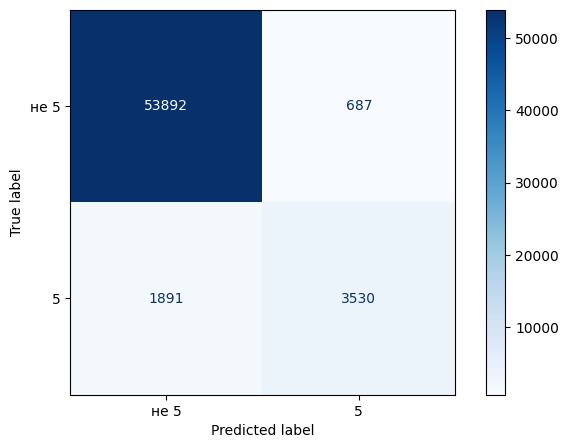

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_train_5, y_train_pred, display_labels=['не 5', '5'], cmap='Blues')
plt.show()

## Точность, полнота и F1-мера

Точность (англ. *precision*) — доля настоящих пятёрок среди всего, что модель назвала пятёркой:

$$\mathrm{precision} = \frac{TP}{TP + FP}$$

Полнота (англ. *recall*) — доля найденных пятёрок среди всех пятёрок:

$$\mathrm{recall} = \frac{TP}{TP + FN}$$

F1-мера (англ. *F1 score*) — гармоническое среднее точности и полноты; она высока, только когда высоки обе:

$$F_1 = \frac{2}{\frac{1}{\mathrm{precision}} + \frac{1}{\mathrm{recall}}} = \frac{2 \cdot \mathrm{precision} \cdot \mathrm{recall}}{\mathrm{precision} + \mathrm{recall}}$$

Сначала — формулами по числам из матрицы:

In [26]:
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

precision, recall, f1

(0.8370879772350012, 0.6511713705958311, 0.7325171197343846)

То же функциями [`sklearn.metrics`](https://scikit-learn.org/1.3/modules/model_evaluation.html#precision-recall-and-f-measures):

In [27]:
from sklearn.metrics import f1_score, precision_score, recall_score

precision_score(y_train_5, y_train_pred), recall_score(y_train_5, y_train_pred), f1_score(y_train_5, y_train_pred)

(0.8370879772350012, 0.6511713705958311, 0.7325171197343846)

Модель с 95 % правильных ответов оказалась не такой хорошей: из того, что она называет пятёркой, верна лишь часть, и находит она не все пятёрки. А «глупый» классификатор не находит ни одной — его полнота равна нулю:

In [28]:
y_train_dummy = cross_val_predict(dummy_clf, X_train, y_train_5, cv=3)
recall_score(y_train_5, y_train_dummy), f1_score(y_train_5, y_train_dummy)

(0.0, 0.0)

Все метрики разом по каждому классу печатает [`classification_report`](https://scikit-learn.org/1.3/modules/generated/sklearn.metrics.classification_report.html):

In [29]:
from sklearn.metrics import classification_report

print(classification_report(y_train_5, y_train_pred, target_names=['не 5', '5']))

              precision    recall  f1-score   support

        не 5       0.97      0.99      0.98     54579
           5       0.84      0.65      0.73      5421

    accuracy                           0.96     60000
   macro avg       0.90      0.82      0.85     60000
weighted avg       0.95      0.96      0.95     60000



Какую метрику ставить выше, решает задача:

| Задача | Чья ошибка дороже | Что важнее |
|---|---|---|
| фильтр видео, безопасных для детей | пропущенное плохое видео (FP) | точность |
| поиск магазинных воров на камерах | пропущенный вор (FN) | полнота |
| поиск мошеннических операций | пропущенное мошенничество (FN) | полнота |
| спам-фильтр | нужное письмо в спаме (FP) | точность |
| нужен баланс, одно число для сравнения | — | F1 |

## Порог принятия решения

Книга: гл. 3, стр. 131–135.

`SGDClassifier` вычисляет для образца оценку $z$ (англ. *decision function*) и относит его к положительному классу, если оценка больше порога принятия решения (англ. *decision threshold*). У `predict` порог равен нулю, но саму оценку можно получить методом `decision_function`:

In [30]:
y_some_score = sgd_clf.decision_function([some_digit])
y_some_score

array([2164.22030239])

In [31]:
threshold = 0
y_some_score > threshold

array([ True])

Поднимем порог — та же пятёрка перестаёт быть пятёркой: точность растёт, полнота падает.

In [32]:
threshold = 8000
y_some_score > threshold

array([False])

### Соотношение точности и полноты

Чтобы выбрать порог, нужны оценки для всей обучающей выборки — снова `cross_val_predict`, но с `method='decision_function'`:

In [33]:
y_scores = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3, method='decision_function')
y_scores[:5]

array([  1200.93051237, -26883.79202424, -33072.03475406, -15919.5480689 ,
       -20003.53970191])

[`precision_recall_curve`](https://scikit-learn.org/1.3/modules/generated/sklearn.metrics.precision_recall_curve.html) перебирает все пороги сразу и возвращает точность и полноту для каждого:

In [34]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_train_5, y_scores)
precisions.shape, recalls.shape, thresholds.shape

((60001,), (60001,), (60000,))

Массивы точности и полноты на один элемент длиннее порогов: последняя точка (точность 1, полнота 0) порога не имеет. На графике её отбрасываем:

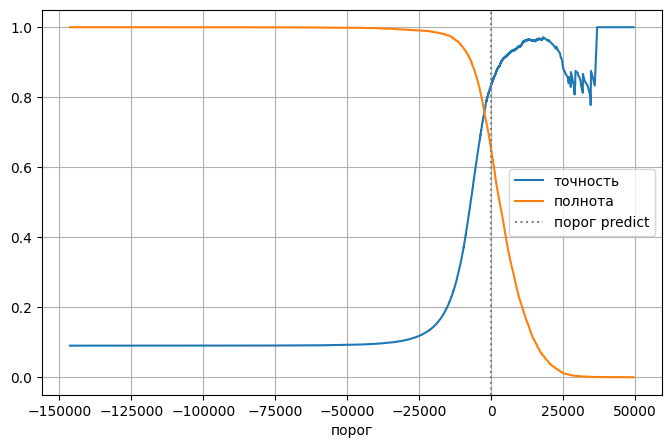

In [35]:
plt.plot(thresholds, precisions[:-1], label='точность')
plt.plot(thresholds, recalls[:-1], label='полнота')
plt.axvline(0, color='gray', linestyle=':', label='порог predict')
plt.xlabel('порог')
plt.legend()
plt.grid(True)
plt.show()

Полнота с ростом порога только падает, а точность в целом растёт, но может и колебаться: убрав с высоким порогом одну верную пятёрку, мы уменьшаем TP. Удобнее смотреть на кривую точности-полноты (англ. *precision-recall curve*):

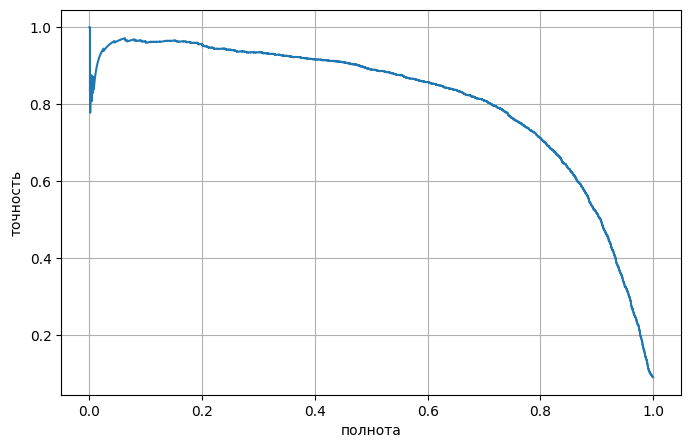

In [36]:
plt.plot(recalls, precisions)
plt.xlabel('полнота')
plt.ylabel('точность')
plt.grid(True)
plt.show()

### Порог под нужную точность

Пусть заказчик просит точность 90 %. Ищем наименьший порог, на котором она достигается: `np.argmax` возвращает индекс первого `True`.

In [37]:
threshold_90_precision = thresholds[np.argmax(precisions[:-1] >= 0.90)]
threshold_90_precision

3370.0194991439557

In [38]:
y_train_pred_90 = (y_scores >= threshold_90_precision)
precision_score(y_train_5, y_train_pred_90), recall_score(y_train_5, y_train_pred_90)

(0.9000345901072293, 0.4799852425751706)

Точность 90 % получить легко — достаточно поднять порог. Вопрос всегда «при какой полноте?»: классификатор с высокой точностью и низкой полнотой бесполезен.

## [ROC-кривая и AUC](https://scikit-learn.org/1.3/modules/model_evaluation.html#receiver-operating-characteristic-roc)

Книга: гл. 3, стр. 135–139.

ROC-кривая (англ. *receiver operating characteristic*) — зависимость доли истинно положительных (TPR — это полнота) от доли ложно положительных (FPR = FP / (FP + TN)) при всех порогах. [`roc_curve`](https://scikit-learn.org/1.3/modules/generated/sklearn.metrics.roc_curve.html) устроена как `precision_recall_curve`:

In [39]:
from sklearn.metrics import roc_curve

fpr, tpr, roc_thresholds = roc_curve(y_train_5, y_scores)
fpr.shape

(3908,)

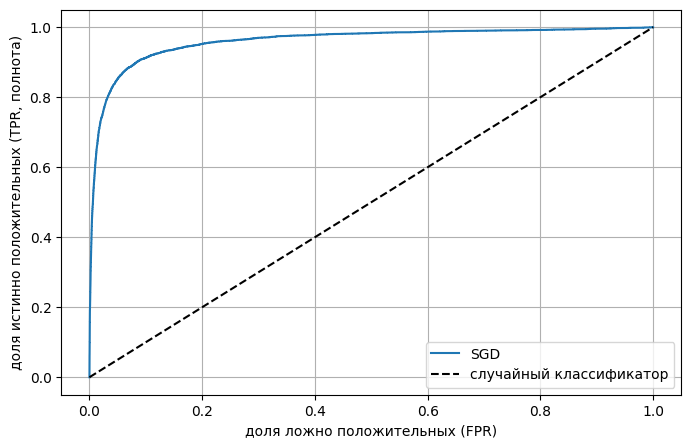

In [40]:
plt.plot(fpr, tpr, label='SGD')
plt.plot([0, 1], [0, 1], 'k--', label='случайный классификатор')
plt.xlabel('доля ложно положительных (FPR)')
plt.ylabel('доля истинно положительных (TPR, полнота)')
plt.legend()
plt.grid(True)
plt.show()

Площадь под кривой (англ. *area under the curve*, AUC) сводит ROC-кривую к одному числу: 1 — идеальный классификатор, 0.5 — случайный.

In [41]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_train_5, y_scores)

0.9604938554008616

### Сравнение SGD и случайного леса

У случайного леса нет `decision_function`, зато есть `predict_proba` — вероятности классов. Получим их честно, через `cross_val_predict` с `method='predict_proba'`:

In [42]:
from sklearn.ensemble import RandomForestClassifier

forest_clf = RandomForestClassifier(random_state=42, n_jobs=-1)
y_probas_forest = cross_val_predict(forest_clf, X_train, y_train_5, cv=3, method='predict_proba')
y_probas_forest[:3]

array([[0.11, 0.89],
       [0.99, 0.01],
       [0.96, 0.04]])

Столбцы — вероятности «не 5» и «5». Оценкой для ROC-кривой служит вероятность положительного класса:

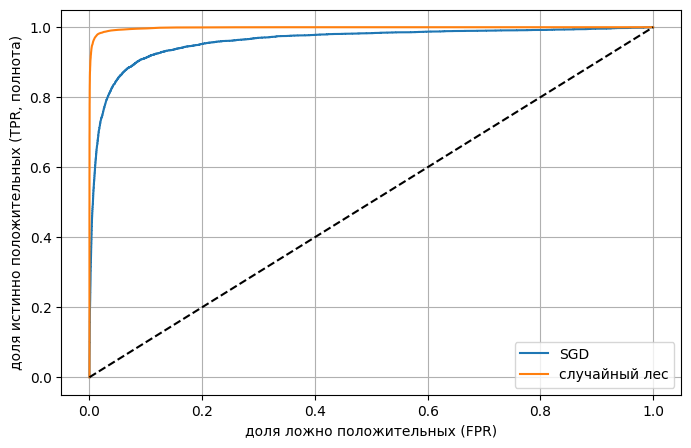

In [43]:
y_scores_forest = y_probas_forest[:, 1]
fpr_forest, tpr_forest, _ = roc_curve(y_train_5, y_scores_forest)

plt.plot(fpr, tpr, label='SGD')
plt.plot(fpr_forest, tpr_forest, label='случайный лес')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('доля ложно положительных (FPR)')
plt.ylabel('доля истинно положительных (TPR, полнота)')
plt.legend()
plt.grid(True)
plt.show()

In [44]:
roc_auc_score(y_train_5, y_scores), roc_auc_score(y_train_5, y_scores_forest)

(0.9604938554008616, 0.9983436731328145)

Кривая леса ближе к левому верхнему углу, его AUC выше. Сравним и кривые точности-полноты, сведя каждую к средней точности [`average_precision_score`](https://scikit-learn.org/1.3/modules/generated/sklearn.metrics.average_precision_score.html) — аналогу площади под PR-кривой:

In [45]:
from sklearn.metrics import average_precision_score

average_precision_score(y_train_5, y_scores), average_precision_score(y_train_5, y_scores_forest)

(0.8100417627526462, 0.98757633833578)

Разрыв между моделями по PR-кривой заметнее, чем по ROC: при редком положительном классе FPR мала у обеих моделей — отрицательных образцов очень много, и сотни ложных срабатываний почти не сдвигают её.

| Когда | Какая кривая |
|---|---|
| положительный класс редкий | PR-кривая |
| ложные срабатывания важнее пропусков | PR-кривая |
| классы примерно сбалансированы | ROC-кривая |
| нужно сравнить модели одним числом без выбора порога | ROC AUC или средняя точность |

# Многоклассовая классификация и анализ ошибок

Книга: гл. 3, стр. 139–146.

Теперь распознаём все десять цифр. Чтобы блокнот выполнялся быстро, в этом разделе учимся на первых 10 000 обучающих изображениях — выводы от этого не меняются, а качество чуть ниже, чем на всей выборке.

In [46]:
X_train_small, y_train_small = X_train[:10_000], y_train[:10_000]
np.bincount(y_train_small)

array([1001, 1127,  991, 1032,  980,  863, 1014, 1070,  944,  978])

## Один против всех и один против одного

Бинарный классификатор можно применить к нескольким классам двумя способами:

- один против всех (англ. *one-versus-all*, *OvA*, *one-versus-the-rest*) — по классификатору на класс («0 / не 0», …, «9 / не 9»), побеждает класс с наибольшей оценкой: 10 классификаторов;
- один против одного (англ. *one-versus-one*, *OvO*) — по классификатору на каждую пару классов: 10 · 9 / 2 = 45 классификаторов, каждый учится на малой части данных.

`SGDClassifier`, получив 10 классов, сам строит схему «один против всех»:

In [47]:
sgd_multi_clf = SGDClassifier(random_state=42)
sgd_multi_clf.fit(X_train_small, y_train_small)
sgd_multi_clf.predict([some_digit])

array([5], dtype=uint8)

Вместо одной оценки — десять, по одной на класс; предсказание — класс с наибольшей:

In [48]:
some_digit_scores = sgd_multi_clf.decision_function([some_digit])
some_digit_scores.round()

array([[-353934., -456279., -118803.,   -9739., -380799.,   37722.,
        -361784., -252474., -142313., -199056.]])

In [49]:
np.argmax(some_digit_scores), sgd_multi_clf.classes_

(5, array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8))

Номер столбца совпал с цифрой только потому, что классы — числа 0–9 по порядку; в общем случае класс берут из `classes_[np.argmax(...)]`.

Схему «один против одного» задаёт обёртка [`OneVsOneClassifier`](https://scikit-learn.org/1.3/modules/generated/sklearn.multiclass.OneVsOneClassifier.html):

In [50]:
from sklearn.multiclass import OneVsOneClassifier

ovo_clf = OneVsOneClassifier(SGDClassifier(random_state=42))
ovo_clf.fit(X_train_small, y_train_small)
ovo_clf.predict([some_digit]), len(ovo_clf.estimators_)

(array([5], dtype=uint8), 45)

## Масштабирование признаков

SGD чувствителен к масштабу признаков (практика 03). Сравним метрики модели без масштабирования и со стандартизацией `StandardScaler` в конвейере. [`cross_validate`](https://scikit-learn.org/1.3/modules/generated/sklearn.model_selection.cross_validate.html), в отличие от `cross_val_score`, считает сразу несколько метрик. Метрики с приставкой `_macro` — точность, полнота и F1, посчитанные для каждой цифры отдельно и усреднённые по десяти классам; подробнее — в факультативном разделе в конце блокнота. Классы MNIST сбалансированы, поэтому доля правильных ответов здесь — честная метрика, и macro-метрики близки к ней.

In [51]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

scaled_sgd_clf = make_pipeline(StandardScaler(), SGDClassifier(random_state=42))
scaling_scoring = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

In [52]:
scaling_scores = {}

for name, clf in [('без масштабирования', sgd_multi_clf), ('со стандартизацией', scaled_sgd_clf)]:
    cv_result = cross_validate(clf, X_train_small, y_train_small, cv=3, scoring=scaling_scoring, n_jobs=-1)
    scaling_scores[name] = {metric: cv_result[f'test_{metric}'].mean() for metric in scaling_scoring}

pd.DataFrame(scaling_scores).T.round(3)

,accuracy,precision_macro,recall_macro,f1_macro
без масштабирования,0.863,0.865,0.861,0.861
со стандартизацией,0.895,0.895,0.894,0.894


Стандартизация поднимает все четыре метрики примерно на три процентных пункта. Дальше работаем с моделью в конвейере.

## Анализ ошибок

Анализ ошибок на лекции не разбирали: идея в том, чтобы посмотреть, **какие** классы модель путает, и понять, что улучшать — данные, признаки или модель. Начинаем с матрицы ошибок 10 × 10:

In [53]:
y_train_small_pred = cross_val_predict(scaled_sgd_clf, X_train_small, y_train_small, cv=3, n_jobs=-1)
conf_mx = confusion_matrix(y_train_small, y_train_small_pred)
conf_mx

array([[ 963,    0,    4,    3,    2,   14,    5,    2,    8,    0],
       [   0, 1069,   11,    6,    1,   14,    0,    2,   23,    1],
       [   9,   17,  865,   13,    8,    7,   13,   12,   43,    4],
       [  10,    9,   29,  876,    1,   44,    4,   16,   25,   18],
       [   2,    4,   12,    5,  873,    5,   10,   10,   18,   41],
       [   6,    4,    9,   39,   17,  715,   14,    1,   47,   11],
       [  11,    4,   15,    0,    7,   15,  941,    2,   18,    1],
       [   4,    2,   12,   10,   11,    1,    1,  960,    8,   61],
       [   8,   16,   24,   15,    2,   17,   14,    4,  836,    8],
       [   7,    7,    9,   21,   24,    4,    0,   33,   19,  854]])

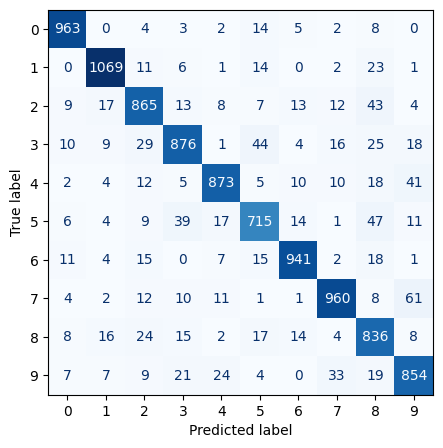

In [54]:
ConfusionMatrixDisplay(conf_mx).plot(cmap='Blues', colorbar=False)
plt.show()

Диагональ яркая — большинство цифр распознано верно — и забивает всё остальное. Чтобы увидеть ошибки:

1. делим каждую строку на число образцов класса: получаем долю ошибок, а не их число — иначе частые классы выглядят хуже;
2. обнуляем диагональ.

In [55]:
row_sums = conf_mx.sum(axis=1, keepdims=True)
norm_conf_mx = conf_mx / row_sums
np.fill_diagonal(norm_conf_mx, 0)
norm_conf_mx.round(3)

array([[0.   , 0.   , 0.004, 0.003, 0.002, 0.014, 0.005, 0.002, 0.008,
        0.   ],
       [0.   , 0.   , 0.01 , 0.005, 0.001, 0.012, 0.   , 0.002, 0.02 ,
        0.001],
       [0.009, 0.017, 0.   , 0.013, 0.008, 0.007, 0.013, 0.012, 0.043,
        0.004],
       [0.01 , 0.009, 0.028, 0.   , 0.001, 0.043, 0.004, 0.016, 0.024,
        0.017],
       [0.002, 0.004, 0.012, 0.005, 0.   , 0.005, 0.01 , 0.01 , 0.018,
        0.042],
       [0.007, 0.005, 0.01 , 0.045, 0.02 , 0.   , 0.016, 0.001, 0.054,
        0.013],
       [0.011, 0.004, 0.015, 0.   , 0.007, 0.015, 0.   , 0.002, 0.018,
        0.001],
       [0.004, 0.002, 0.011, 0.009, 0.01 , 0.001, 0.001, 0.   , 0.007,
        0.057],
       [0.008, 0.017, 0.025, 0.016, 0.002, 0.018, 0.015, 0.004, 0.   ,
        0.008],
       [0.007, 0.007, 0.009, 0.021, 0.025, 0.004, 0.   , 0.034, 0.019,
        0.   ]])

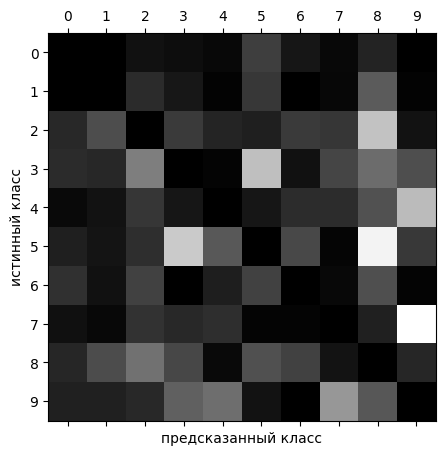

In [56]:
plt.matshow(norm_conf_mx, cmap='gray')
plt.xlabel('предсказанный класс')
plt.ylabel('истинный класс')
plt.xticks(range(10))
plt.yticks(range(10))
plt.show()

Строки — истинные классы, столбцы — предсказанные. Светлый столбец — класс, к которому модель тянет чужие цифры; светлая клетка — пара, которую она путает. Найдём самую частую путаницу программно:

In [57]:
true_class, pred_class = np.unravel_index(np.argmax(norm_conf_mx), norm_conf_mx.shape)
true_class, pred_class, norm_conf_mx[true_class, pred_class].round(3)

(7, 9, 0.057)

Чаще всего модель принимает семёрки за девятки. Посмотрим на другую заметную пару — «3» и «5», её разбирает и книга: какие тройки модель приняла за пятёрки и наоборот.

In [58]:
digit_a, digit_b = 3, 5
mask_ab = (y_train_small == digit_a) & (y_train_small_pred == digit_b)
mask_ba = (y_train_small == digit_b) & (y_train_small_pred == digit_a)
mask_ab.sum(), mask_ba.sum()

(44, 39)

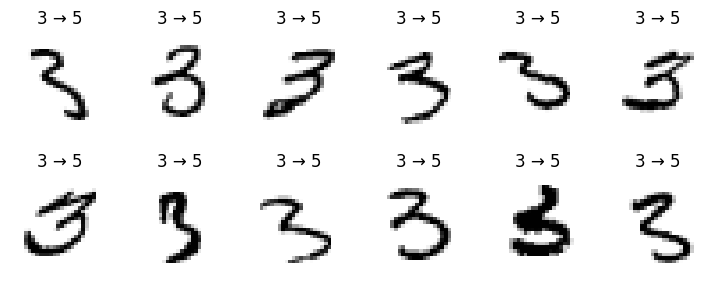

In [59]:
plot_digits(X_train_small[mask_ab][:12], [f'{digit_a} → {digit_b}'] * 12)

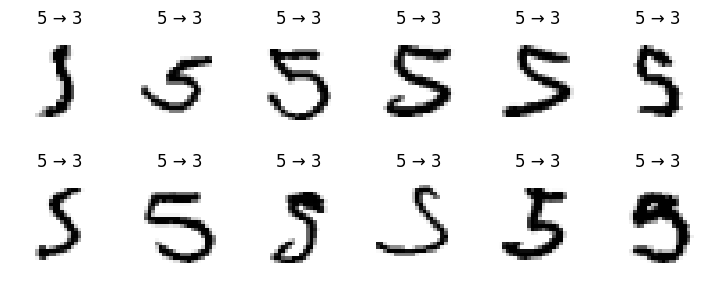

In [60]:
plot_digits(X_train_small[mask_ba][:12], [f'{digit_b} → {digit_a}'] * 12)

Многие ошибки понятны и человеку: тройка и пятёрка различаются лишь отрезком, соединяющим верх и дугу. Линейная модель присваивает вес каждому пикселю, поэтому чувствительна к сдвигу и повороту цифры. Что можно сделать: центрировать и выпрямлять изображения, добавить признаки (например, число замкнутых контуров) или взять более гибкую модель.

## Сравнение моделей

Сравним шесть моделей scikit-learn с параметрами по умолчанию на тех же 10 000 изображениях, все — со стандартизацией в конвейере. Метрика — F1-мера с macro-усреднением (`f1_macro`).

In [61]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier

models = [
    LogisticRegression(max_iter=1000),
    SGDClassifier(random_state=42),
    KNeighborsClassifier(),
    DecisionTreeClassifier(random_state=42),
    RandomForestClassifier(random_state=42),
    MLPClassifier(random_state=42),
]

Обучение занимает около минуты.

In [62]:
scores = {}
scoring = ['accuracy', 'f1_macro']

for model in models:
    pipeline = make_pipeline(StandardScaler(), model)
    cv_result = cross_validate(pipeline, X_train_small, y_train_small, cv=3, scoring=scoring, n_jobs=-1)
    scores[type(model).__name__] = {
        'fit_time': cv_result['fit_time'].mean(),
        'accuracy': cv_result['test_accuracy'].mean(),
        'f1_macro': cv_result['test_f1_macro'].mean(),
    }

In [63]:
models_comparison = pd.DataFrame(scores).T.sort_values('f1_macro', ascending=False)
models_comparison.round(3)

,fit_time,accuracy,f1_macro
RandomForestClassifier,2.545,0.941,0.940
MLPClassifier,5.695,0.935,0.934
KNeighborsClassifier,0.082,0.897,0.896
SGDClassifier,16.322,0.895,0.894
LogisticRegression,8.387,0.885,0.882
DecisionTreeClassifier,1.040,0.789,0.785


Впереди случайный лес и многослойный персептрон, в середине метод ближайших соседей и линейные модели, последнее — одиночное дерево решений: без ансамбля оно сильно переобучается. Ансамбли разберём в практике 08, нейронные сети — в блоке C.

# Задание: мошеннические операции

Банк хочет автоматически находить мошеннические операции по картам. Мошенничество редкое — около 3,5 % операций, и пропущенное мошенничество обходится банку гораздо дороже, чем лишняя проверка честной операции.

Данные сгенерированы функцией ниже и записаны в `data/transactions.csv`: десять обезличенных числовых признаков `feature_0` … `feature_9` и целевой признак `is_fraud` (1 — мошенничество). Выполните ячейку и работайте с файлом.

In [64]:
from pathlib import Path

from sklearn.datasets import make_classification


def make_transactions_csv(path, seed=0):
    """Генерирует набор карточных операций с редким классом «мошенничество» и пишет его в CSV.

    Args:
        path: Путь к CSV-файлу.
        seed: Зерно генератора случайных чисел.

    Returns:
        Путь к записанному файлу.
    """
    features, labels = make_classification(
        n_samples=20_000,
        n_features=10,
        n_informative=5,
        n_redundant=2,
        weights=[0.97],
        flip_y=0.01,
        class_sep=0.8,
        random_state=seed,
    )
    transactions = pd.DataFrame(features, columns=[f'feature_{i}' for i in range(features.shape[1])])
    transactions['is_fraud'] = labels
    path.parent.mkdir(parents=True, exist_ok=True)
    transactions.to_csv(path, index=False)
    return path


transactions_path = make_transactions_csv(Path('data') / 'transactions.csv')
transactions_path

PosixPath('data/transactions.csv')

### Задание 1

Загрузите `data/transactions.csv` в `transactions_task`, отделите признаки `X_task` от целевого признака `y_task`. Какова доля мошеннических операций? Какую долю правильных ответов при перекрёстной проверке по 3 блокам даёт `DummyClassifier`, всегда отвечающий «не мошенничество», и какова его полнота?

### Задание 2

Соберите конвейер `make_pipeline(StandardScaler(), LogisticRegression())` и получите для него честные предсказания `cross_val_predict` (3 блока). Постройте матрицу ошибок и посчитайте точность, полноту и F1. Объясните словами, что означают числа FP и FN для банка.

### Задание 3

Банк требует находить не меньше 90 % мошеннических операций. Получите оценки модели из задания 2 (`method='decision_function'`), с помощью `precision_recall_curve` найдите **наибольший** порог, при котором полнота не ниже 0.9. Какая точность получается при этом пороге? Сколько честных операций придётся проверять вручную на каждую найденную мошенническую?

### Задание 4

Сравните логистическую регрессию из задания 2 со случайным лесом `RandomForestClassifier(random_state=42)` по двум метрикам: `roc_auc_score` и `average_precision_score` (вероятности — `cross_val_predict(..., method='predict_proba')`). Нарисуйте ROC-кривые и кривые точности-полноты обеих моделей. Какая модель лучше и почему разница между ними по ROC AUC меньше, чем по средней точности?

# Решение

### Задание 1

In [65]:
transactions_task = pd.read_csv(Path('data') / 'transactions.csv')
X_task = transactions_task.drop(columns='is_fraud')
y_task = transactions_task['is_fraud']

transactions_task.shape, y_task.mean()

((20000, 11), 0.0354)

In [66]:
dummy_task = DummyClassifier(strategy='most_frequent')
dummy_accuracy_task = cross_val_score(dummy_task, X_task, y_task, cv=3, scoring='accuracy')
y_dummy_task = cross_val_predict(dummy_task, X_task, y_task, cv=3)

dummy_accuracy_task.mean(), recall_score(y_task, y_dummy_task)

(0.9645999998229912, 0.0)

«Глупый» классификатор даёт около 96 % правильных ответов и не находит ни одной мошеннической операции.

### Задание 2

In [67]:
logreg_task = make_pipeline(StandardScaler(), LogisticRegression())
y_pred_task = cross_val_predict(logreg_task, X_task, y_task, cv=3)

confusion_matrix(y_task, y_pred_task)

array([[19276,    16],
       [  420,   288]])

In [68]:
precision_score(y_task, y_pred_task), recall_score(y_task, y_pred_task), f1_score(y_task, y_pred_task)

(0.9473684210526315, 0.4067796610169492, 0.5691699604743082)

FP — честные операции, принятые за мошенничество: лишняя ручная проверка и недовольный клиент. FN — пропущенное мошенничество: прямые потери банка. При пороге по умолчанию модель пропускает большую часть мошенничества — полнота низкая.

### Задание 3

In [69]:
y_scores_task = cross_val_predict(logreg_task, X_task, y_task, cv=3, method='decision_function')
precisions_task, recalls_task, thresholds_task = precision_recall_curve(y_task, y_scores_task)

# Полнота убывает с ростом порога, поэтому последний подходящий порог — наибольший
threshold_90_recall_task = thresholds_task[recalls_task[:-1] >= 0.9].max()
threshold_90_recall_task

-5.093967326114033

In [70]:
y_pred_90_task = (y_scores_task >= threshold_90_recall_task)
precision_90_task = precision_score(y_task, y_pred_90_task)

recall_score(y_task, y_pred_90_task), precision_90_task, (1 - precision_90_task) / precision_90_task

(0.9011299435028248, 0.056053417677033916, 16.84012539184953)

Чтобы находить 90 % мошенничества, порог приходится сильно опустить: точность падает, и на каждую найденную мошенническую операцию приходится больше десятка ложных срабатываний (последнее число).

### Задание 4

In [71]:
forest_task = RandomForestClassifier(random_state=42, n_jobs=-1)
y_proba_logreg_task = cross_val_predict(logreg_task, X_task, y_task, cv=3, method='predict_proba')[:, 1]
y_proba_forest_task = cross_val_predict(forest_task, X_task, y_task, cv=3, method='predict_proba')[:, 1]

pd.DataFrame(
    {
        'roc_auc': [roc_auc_score(y_task, y_proba_logreg_task), roc_auc_score(y_task, y_proba_forest_task)],
        'average_precision': [
            average_precision_score(y_task, y_proba_logreg_task),
            average_precision_score(y_task, y_proba_forest_task),
        ],
    },
    index=['логистическая регрессия', 'случайный лес'],
).round(3)

,roc_auc,average_precision
логистическая регрессия,0.860,0.621
случайный лес,0.903,0.731


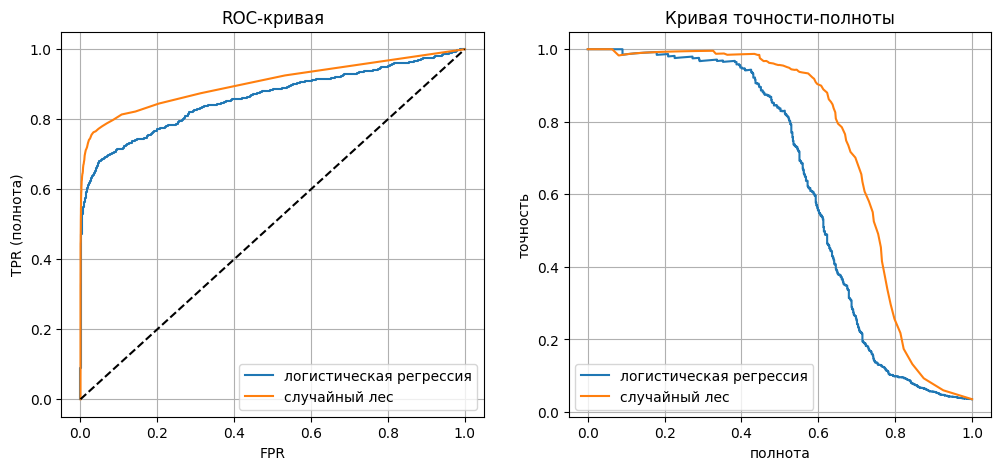

In [72]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))

for name, y_proba in [('логистическая регрессия', y_proba_logreg_task), ('случайный лес', y_proba_forest_task)]:
    fpr_task, tpr_task, _ = roc_curve(y_task, y_proba)
    precisions_curve, recalls_curve, _ = precision_recall_curve(y_task, y_proba)
    ax_roc.plot(fpr_task, tpr_task, label=name)
    ax_pr.plot(recalls_curve, precisions_curve, label=name)

ax_roc.plot([0, 1], [0, 1], 'k--')
ax_roc.set(xlabel='FPR', ylabel='TPR (полнота)', title='ROC-кривая')
ax_pr.set(xlabel='полнота', ylabel='точность', title='Кривая точности-полноты')

for ax in (ax_roc, ax_pr):
    ax.legend()
    ax.grid(True)

plt.show()

Случайный лес лучше по обеим метрикам: признаки связаны с классом нелинейно, а линейная модель этого не улавливает. Разница по ROC AUC меньше, потому что FPR делится на огромное число честных операций (~96 % выборки): даже сотни лишних ложных срабатываний почти не сдвигают ROC-кривую. Точность делится на число срабатываний модели и сразу реагирует на ложные тревоги, поэтому при редком положительном классе модели сравнивают по кривой точности-полноты.

# Факультативно: macro- и micro-усреднение

Раздел для самостоятельного чтения: как усредняются метрики в многоклассовой задаче.

Точность, полнота и F1 определены для двух классов: «свой» против «чужих». Для нескольких классов их считают по каждому классу отдельно, а потом усредняют одним из двух способов — macro или micro. Разберём на пальцах.

Модель сортирует 10 фотографий: 6 кошек, 3 собаки и 1 кролика. Она узнала всех кошек и две собаки из трёх — третью собаку назвала кошкой; кролика тоже назвала кошкой. Полнота класса — какую долю его фотографий модель нашла:

| Класс | Было фото | Найдено | Полнота |
|---|---|---|---|
| кошка | 6 | 6 | 6 / 6 = 1.00 |
| собака | 3 | 2 | 2 / 3 ≈ 0.67 |
| кролик | 1 | 0 | 0 / 1 = 0.00 |
| **всего** | **10** | **8** | |

**Macro** — сначала метрика каждого класса, потом простое среднее по классам: (1.00 + 0.67 + 0.00) / 3 ≈ 0.56. У каждого класса один голос, поэтому единственный пропущенный кролик тянет оценку вниз так же сильно, как шесть верно найденных кошек — вверх.

**Micro** — сначала складываем найденное по всем классам, потом делим один раз: (6 + 2 + 0) / 10 = 0.80. У каждой фотографии один голос, а кролик — лишь одна фотография из десяти. Это ровно доля правильных ответов: 8 верных ответов из 10.

Точность усредняется так же, только считается по предсказаниям модели, а не по истинным классам: кошкой модель назвала 8 фото, кошек среди них 6 — точность 6 / 8 = 0.75; собакой — 2 фото, обе собаки — 1.00; кроликом — ни одного, точность не определена, и scikit-learn считает её нулём (параметр `zero_division`). Macro-точность (0.75 + 1.00 + 0.00) / 3 ≈ 0.58, micro-точность — снова 8 / 10 = 0.80.

Итог: macro — когда важен каждый класс, особенно редкий; micro — когда важен каждый объект.

Тот же пример в коде:

In [73]:
y_true_toy = ['кошка'] * 6 + ['собака'] * 3 + ['кролик']
y_pred_toy = ['кошка'] * 6 + ['собака', 'собака', 'кошка'] + ['кошка']
toy_labels = ['кошка', 'собака', 'кролик']

confusion_matrix(y_true_toy, y_pred_toy, labels=toy_labels)

array([[6, 0, 0],
       [1, 2, 0],
       [1, 0, 0]])

## Ловушка: метрика без `average`

По умолчанию метрики scikit-learn ждут два класса. Как неправильно:

In [74]:
try:
    recall_score(y_true_toy, y_pred_toy)
except ValueError as error:
    print(error)

Target is multiclass but average='binary'. Please choose another average setting, one of [None, 'micro', 'macro', 'weighted'].


Как правильно — указать способ усреднения. `average=None` возвращает метрику каждого класса; `labels` задаёт порядок классов, иначе они идут по алфавиту:

In [75]:
recall_score(y_true_toy, y_pred_toy, labels=toy_labels, average=None)

array([1.        , 0.66666667, 0.        ])

In [76]:
recall_score(y_true_toy, y_pred_toy, average='macro'), recall_score(y_true_toy, y_pred_toy, average='micro')

(0.5555555555555555, 0.8)

In [77]:
precision_score(y_true_toy, y_pred_toy, labels=toy_labels, average=None, zero_division=0)

array([0.75, 1.  , 0.  ])

In [78]:
(
    precision_score(y_true_toy, y_pred_toy, average='macro', zero_division=0),
    precision_score(y_true_toy, y_pred_toy, average='micro'),
)

(0.5833333333333334, 0.8)

Micro-метрики совпали с долей правильных ответов:

In [79]:
from sklearn.metrics import accuracy_score

accuracy_score(y_true_toy, y_pred_toy)

0.8

`classification_report` печатает всё сразу; строка `weighted avg` — среднее, взвешенное по числу образцов класса:

In [80]:
print(classification_report(y_true_toy, y_pred_toy, labels=toy_labels, zero_division=0))

              precision    recall  f1-score   support

       кошка       0.75      1.00      0.86         6
      собака       1.00      0.67      0.80         3
      кролик       0.00      0.00      0.00         1

    accuracy                           0.80        10
   macro avg       0.58      0.56      0.55        10
weighted avg       0.75      0.80      0.75        10

